In [1]:
from cropspectai import ml_config
from cropspectai.data_analysis.preprocessing import split_dataset_into_X_y
from cropspectai.data_analysis import downsampling
import pandas as pd

# train data

In [2]:
train_path = ml_config.RAW_PARQUET_DATA_SPLITS_PATH / "train.parquet"
df_train = pd.read_parquet(train_path)

X_train, y_train = split_dataset_into_X_y(df_train)

wavelengths = X_train.columns.astype(int).to_numpy()
srf_df = downsampling.generate_gaussian_srfs(wavelengths)
srf_df.head()

,F1,F2,FZ,F3,F4,FY,F5,FXL,F6,F7,F8,NIR
wavelength,,,,,,,,,,,,
400,0.925875,0.027867,0.101125,2.980234e-08,1.114798e-10,0.001280,7.647357e-23,2.980234e-08,1.807493e-28,3.337917e-34,1.544488e-40,3.251074e-86
401,0.951905,0.036898,0.110730,4.716275e-08,1.657814e-10,0.001394,1.504579e-22,3.542581e-08,3.074582e-28,5.674793e-34,2.625668e-40,7.715875e-86
402,0.972655,0.048298,0.121026,7.417748e-08,2.456803e-10,0.001518,2.946813e-22,4.207390e-08,5.218337e-28,9.630047e-34,4.456829e-40,1.827754e-85
403,0.987753,0.062500,0.132036,1.159496e-07,3.628271e-10,0.001652,5.745454e-22,4.992632e-08,8.837205e-28,1.631213e-33,7.553413e-40,4.321398e-85
404,0.996924,0.079957,0.143785,1.801318e-07,5.339787e-10,0.001797,1.115142e-21,5.919296e-08,1.493256e-27,2.758017e-33,1.278179e-39,1.019777e-84


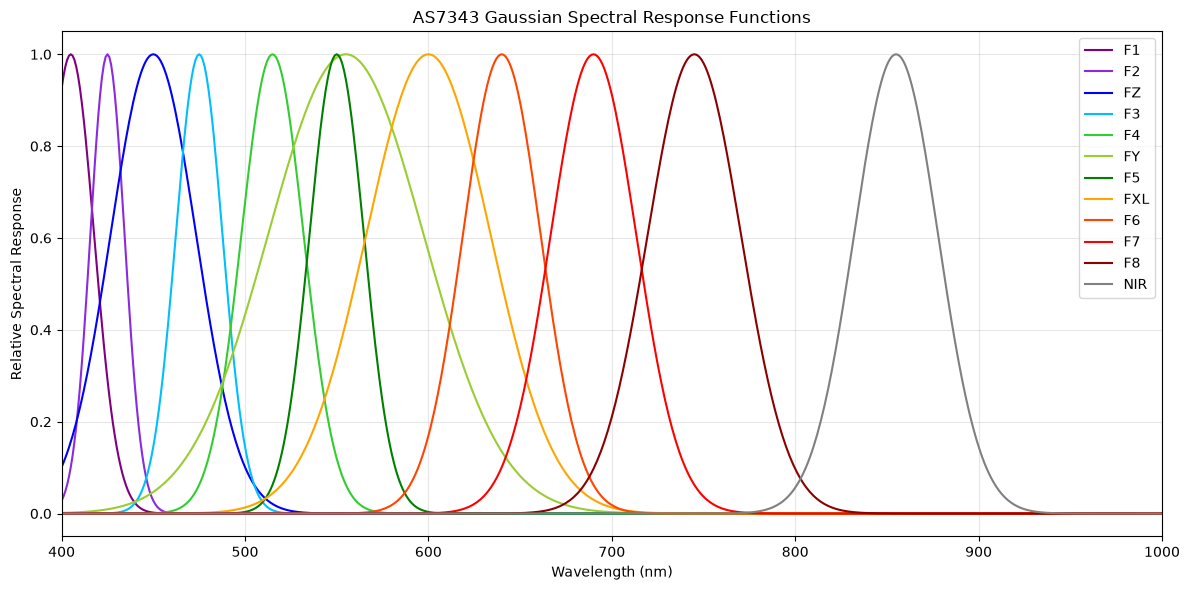

In [3]:
downsampling.plot_srfs(srf_df)

## downsampleple to as7343

In [4]:
reflectance_df = downsampling.downsample_to_as7343(X_train, wavelengths, srf_df)
reflectance_df.head()

,F1,F2,FZ,F3,F4,FY,F5,FXL,F6,F7,F8,NIR
0,0.025957,0.027368,0.029785,0.031936,0.042845,0.050369,0.053511,0.054448,0.053959,0.087360,0.184137,0.252295
1,0.018796,0.019208,0.020494,0.022136,0.039216,0.046919,0.054891,0.046365,0.037027,0.090236,0.281759,0.409710
2,0.013159,0.012412,0.012061,0.012497,0.024823,0.029880,0.036110,0.028813,0.022168,0.082306,0.319665,0.488143
3,0.075124,0.074951,0.072234,0.068406,0.066445,0.064640,0.069012,0.057717,0.048425,0.107107,0.329112,0.478977
4,0.016363,0.018973,0.023530,0.027460,0.045687,0.058501,0.067127,0.060657,0.050353,0.136434,0.414128,0.570908


In [5]:
X_train.head()

,400,401,402,403,404,405,406,407,408,409,...,2441,2442,2443,2444,2445,2446,2447,2448,2449,2450
0,0.024606,0.024717,0.024828,0.024939,0.025049,0.025160,0.025271,0.025382,0.025493,0.025603,...,0.066124,0.065813,0.065501,0.065189,0.064877,0.064566,0.064254,0.063942,0.063631,0.063319
1,0.018385,0.018419,0.018453,0.018487,0.018521,0.018554,0.018588,0.018622,0.018656,0.018690,...,0.025684,0.025596,0.025509,0.025421,0.025334,0.025246,0.025158,0.025071,0.024983,0.024895
2,0.013855,0.013798,0.013741,0.013684,0.013628,0.013571,0.013514,0.013457,0.013400,0.013344,...,0.024341,0.024249,0.024158,0.024066,0.023975,0.023883,0.023791,0.023700,0.023608,0.023517
3,0.075291,0.075278,0.075264,0.075250,0.075236,0.075222,0.075208,0.075195,0.075181,0.075167,...,0.023813,0.023637,0.023462,0.023286,0.023110,0.022935,0.022759,0.022583,0.022408,0.022232
4,0.013860,0.014065,0.014271,0.014476,0.014681,0.014887,0.015092,0.015297,0.015503,0.015708,...,0.065621,0.065400,0.065179,0.064957,0.064736,0.064515,0.064293,0.064072,0.063851,0.063629


In [6]:
y_train.head()

,cab,cw,cm,LAI,cp,cbc,car,anth
0,37.111931,NaN,0.003632,NaN,0.000337,0.003295,7.570210,NaN
1,43.731911,0.033507,0.013546,NaN,0.001114,0.012433,17.536637,NaN
2,54.466597,0.014103,0.007543,NaN,0.000786,0.006756,10.241632,NaN
3,NaN,NaN,0.008915,NaN,0.000780,0.008135,NaN,NaN
4,NaN,NaN,0.006693,NaN,0.000836,0.005857,NaN,NaN


## combine x_train and y_train

In [7]:
downsampled_train = pd.concat(
    [reflectance_df, y_train],
    axis=1,
)

In [8]:
downsampled_train.head()

,F1,F2,FZ,F3,F4,FY,F5,FXL,F6,F7,F8,NIR,cab,cw,cm,LAI,cp,cbc,car,anth
0,0.025957,0.027368,0.029785,0.031936,0.042845,0.050369,0.053511,0.054448,0.053959,0.087360,0.184137,0.252295,37.111931,NaN,0.003632,NaN,0.000337,0.003295,7.570210,NaN
1,0.018796,0.019208,0.020494,0.022136,0.039216,0.046919,0.054891,0.046365,0.037027,0.090236,0.281759,0.409710,43.731911,0.033507,0.013546,NaN,0.001114,0.012433,17.536637,NaN
2,0.013159,0.012412,0.012061,0.012497,0.024823,0.029880,0.036110,0.028813,0.022168,0.082306,0.319665,0.488143,54.466597,0.014103,0.007543,NaN,0.000786,0.006756,10.241632,NaN
3,0.075124,0.074951,0.072234,0.068406,0.066445,0.064640,0.069012,0.057717,0.048425,0.107107,0.329112,0.478977,NaN,NaN,0.008915,NaN,0.000780,0.008135,NaN,NaN
4,0.016363,0.018973,0.023530,0.027460,0.045687,0.058501,0.067127,0.060657,0.050353,0.136434,0.414128,0.570908,NaN,NaN,0.006693,NaN,0.000836,0.005857,NaN,NaN


## save train data to downsampled

In [ ]:
output_path = ml_config.DOWNSAMPLED_PARQUET_DATA_SPLITS_PATH / "train.parquet"

downsampled_train.to_parquet(
    output_path,
    engine="pyarrow",
    index=False,
)

# test data

In [12]:
test_path = ml_config.RAW_PARQUET_DATA_SPLITS_PATH / "test.parquet"
df_test = pd.read_parquet(test_path)

X_test, y_test = split_dataset_into_X_y(df_test)

wavelengths = X_test.columns.astype(int).to_numpy()
srf_df = downsampling.generate_gaussian_srfs(wavelengths)
srf_df.head()

,F1,F2,FZ,F3,F4,FY,F5,FXL,F6,F7,F8,NIR
wavelength,,,,,,,,,,,,
400,0.925875,0.027867,0.101125,2.980234e-08,1.114798e-10,0.001280,7.647357e-23,2.980234e-08,1.807493e-28,3.337917e-34,1.544488e-40,3.251074e-86
401,0.951905,0.036898,0.110730,4.716275e-08,1.657814e-10,0.001394,1.504579e-22,3.542581e-08,3.074582e-28,5.674793e-34,2.625668e-40,7.715875e-86
402,0.972655,0.048298,0.121026,7.417748e-08,2.456803e-10,0.001518,2.946813e-22,4.207390e-08,5.218337e-28,9.630047e-34,4.456829e-40,1.827754e-85
403,0.987753,0.062500,0.132036,1.159496e-07,3.628271e-10,0.001652,5.745454e-22,4.992632e-08,8.837205e-28,1.631213e-33,7.553413e-40,4.321398e-85
404,0.996924,0.079957,0.143785,1.801318e-07,5.339787e-10,0.001797,1.115142e-21,5.919296e-08,1.493256e-27,2.758017e-33,1.278179e-39,1.019777e-84


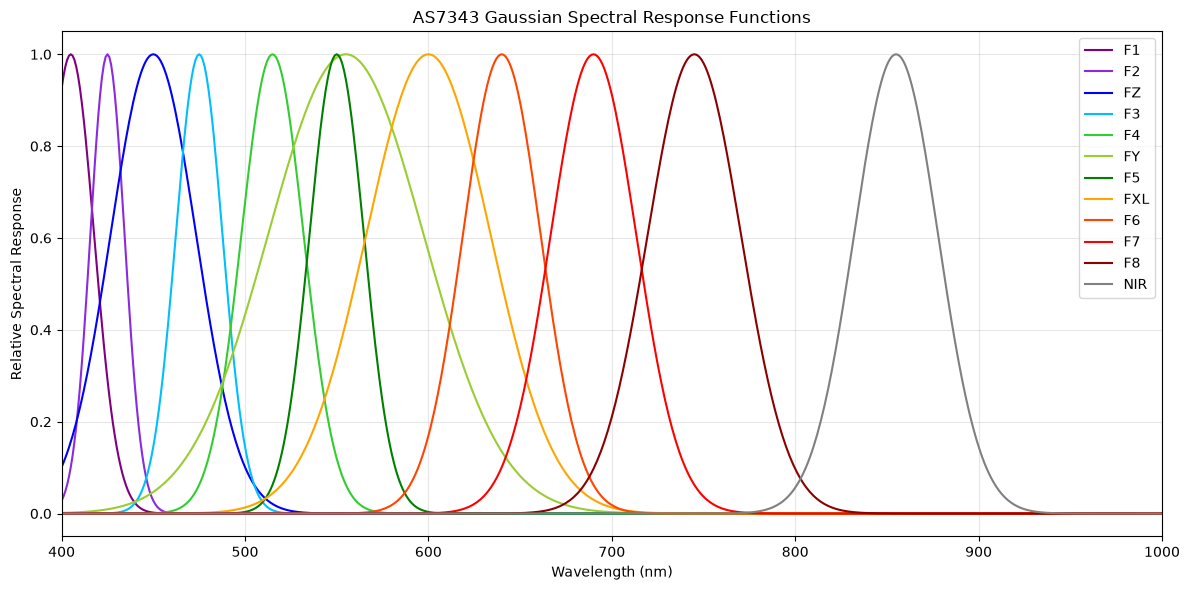

In [13]:
downsampling.plot_srfs(srf_df)

## downsample to AS7343 - test

In [14]:
reflectance_df = downsampling.downsample_to_as7343(X_test, wavelengths, srf_df)
reflectance_df.head()

,F1,F2,FZ,F3,F4,FY,F5,FXL,F6,F7,F8,NIR
0,0.016513,0.016457,0.016776,0.017450,0.030144,0.037907,0.043301,0.039655,0.034654,0.089615,0.255555,0.373916
1,0.000442,0.001711,0.005441,0.009058,0.020400,0.025401,0.030119,0.025973,0.022076,0.076948,0.238041,0.344627
2,0.015144,0.018693,0.025499,0.031722,0.052933,0.067848,0.073569,0.076306,0.075691,0.125281,0.264543,0.377517
3,0.020416,0.019752,0.018942,0.018570,0.028029,0.032276,0.037771,0.031083,0.025547,0.098380,0.357622,0.530911
4,0.034442,0.036906,0.041056,0.044699,0.061008,0.069777,0.076215,0.071924,0.066817,0.107477,0.234443,0.306557


## combine x_test and y_test

In [16]:
downsampled_test = pd.concat(
    [reflectance_df, y_test],
    axis=1,
)

In [17]:
downsampled_test.head()

,F1,F2,FZ,F3,F4,FY,F5,FXL,F6,F7,F8,NIR,cab,cw,cm,LAI,cp,cbc,car,anth
0,0.016513,0.016457,0.016776,0.017450,0.030144,0.037907,0.043301,0.039655,0.034654,0.089615,0.255555,0.373916,NaN,0.008478,0.005011,NaN,0.000472,0.004539,NaN,NaN
1,0.000442,0.001711,0.005441,0.009058,0.020400,0.025401,0.030119,0.025973,0.022076,0.076948,0.238041,0.344627,53.332737,0.022489,0.023083,NaN,0.001630,0.021454,8.642805,NaN
2,0.015144,0.018693,0.025499,0.031722,0.052933,0.067848,0.073569,0.076306,0.075691,0.125281,0.264543,0.377517,23.218480,0.017624,0.007158,NaN,0.000508,0.006650,4.125131,NaN
3,0.020416,0.019752,0.018942,0.018570,0.028029,0.032276,0.037771,0.031083,0.025547,0.098380,0.357622,0.530911,34.646462,NaN,0.008545,NaN,0.001070,0.007475,8.298752,NaN
4,0.034442,0.036906,0.041056,0.044699,0.061008,0.069777,0.076215,0.071924,0.066817,0.107477,0.234443,0.306557,24.006633,0.008120,0.008152,NaN,0.000555,0.007597,6.019155,NaN


## save test data to downsampled

In [ ]:
output_path = ml_config.DOWNSAMPLED_PARQUET_DATA_SPLITS_PATH / "test.parquet"

downsampled_test.to_parquet(
    output_path,
    engine="pyarrow",
    index=False,
)